In [1]:
from __future__ import annotations
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import mean_absolute_error, r2_score
import sys
from tabpfn import TabPFNRegressor
project_root = Path.cwd().parent

modules_path = project_root / "modules"
sys.path.append(str(modules_path))



/home/andre/miniconda3/envs/chem/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Fit/Train model
* I have selected MACE OFF (Large) as the test model + I am using impact sensitvity as a test datasets.
* I trained a full sweep of seeds/datasets/regressors/embeddings 260611 which has training results as well but want to keep this notebook self contained for the sake of prototyping

As a note, the dataset has a size of mace_embds.shape = (305, 448)

In [2]:
mace_embds = np.load(f"{project_root}/02_EMBEDDINGS/log(h50)_exp/maceoff_large_embeddings.npy")
dataset = pd.read_csv(f"{project_root}/01_DATASETS/log(h50)_exp/log(h50)_exp.csv")
ys = dataset["val"].values

test_split_idx = np.load(f"{project_root}/01_DATASETS/log(h50)_exp/random_seed0_split_test.npy")

train_idx = np.setdiff1d(np.arange(len(dataset)), test_split_idx)
train_x = mace_embds[train_idx]
train_y = ys[train_idx]
test_x = mace_embds[test_split_idx]
test_y = ys[test_split_idx]

In [ ]:
model = TabPFNRegressor()
model.fit(train_x, train_y)
predictions = model.predict(test_x)

# Evaluate the model
mae = mean_absolute_error(test_y, predictions)
r2 = r2_score(test_y, predictions)
print(f"Mean Absolute Error: {mae}")
print(f"R^2 Score: {r2}")

/home/andre/miniconda3/envs/chem/lib/python3.11/site-packages/tabpfn/validation.py:142: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(


Mean Absolute Error: 0.19726301349804382
R^2 Score: 0.6707992907633853


In [ ]:
# result from mlp with the same dataset / split 
mae_values = np.array([0.236, 0.232, 0.192, 0.227, 0.246], dtype=float)

{"MAE_mean": float(mae_values.mean()), "MAE_std": float(mae_values.std(ddof=1))}

{'MAE_mean': 0.2266, 'MAE_std': 0.020562101059959797}

## Investigate probability distribution
* paper said there was a way to get the probaility distribution for the final outcome which should be a proxy (is a proxy?) for the model uncertainty 
* i am imagining that i can get sd for each datapoint and then make a parity plot with the error bar

Thing to note: TabPFM breaks down the regression into bins (in this case 5000 bins) where instead of predicting a "number" in the pure sence in predicts a class label. Which is why the x axis is "class index" instead of "Impact Sensitivity" -- I am unsure if I can neatly / easily convert the class labels to the corresponding real values

In [30]:
prediction_distribution = model.predict(test_x, output_type="full")

/tmp/ipykernel_18275/1190996430.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = torch.tensor(prediction_distribution["logits"]).cpu()


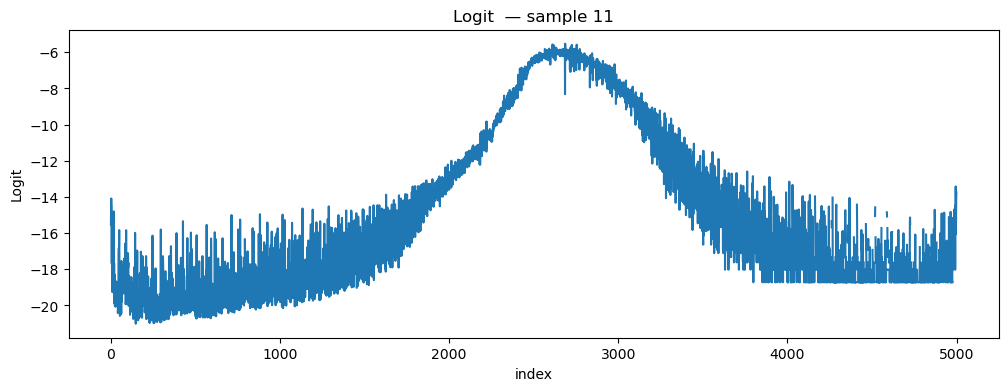

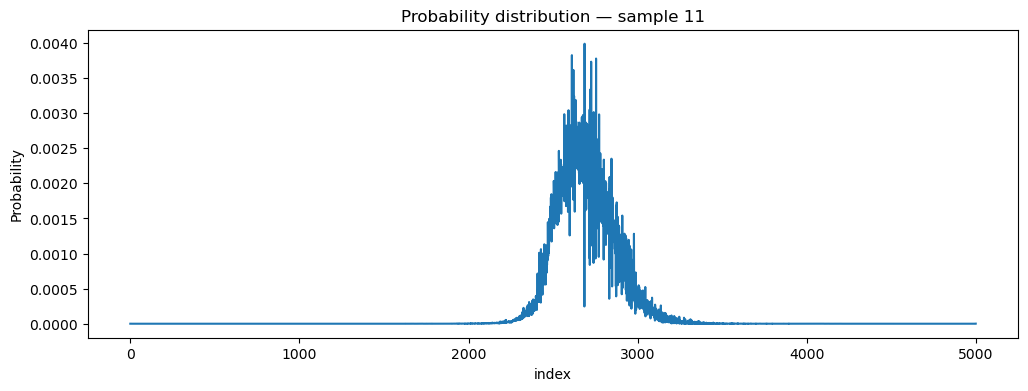

In [75]:
logits = torch.tensor(prediction_distribution["logits"]).cpu()
output_probs = torch.softmax(logits, dim=-1).numpy()

sample = 11

plt.figure(figsize=(12, 4))
plt.plot(logits[sample])

plt.xlabel("index")
plt.ylabel("Logit")
plt.title(f"Logit  — sample {sample}")

plt.show()

plt.figure(figsize=(12, 4))
plt.plot(output_probs[sample])

plt.xlabel("index")
plt.ylabel("Probability")
plt.title(f"Probability distribution — sample {sample}")

plt.show()

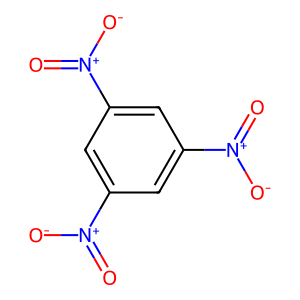

In [14]:
from rdkit import Chem
elv_mol = dataset.iloc[test_split_idx].reset_index(drop=True).iloc[11]["SMILES"]
rdkit_mol = Chem.MolFromSmiles(elv_mol)
Chem.Draw.MolToImage(rdkit_mol, size=(300, 300), kekulize=True, wedgeBonds=True, bgcolor=(255, 255, 255))

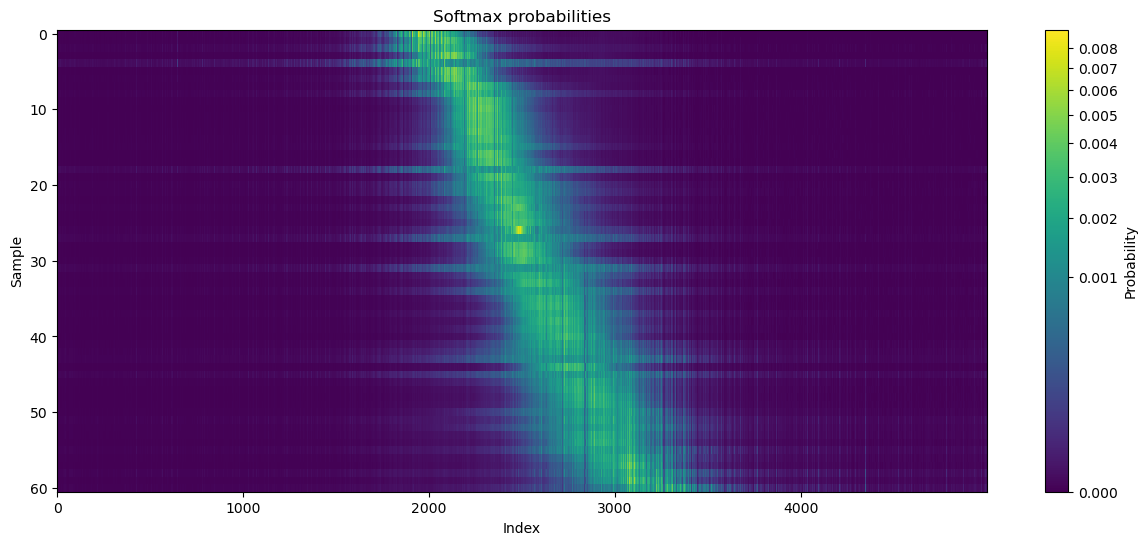

In [96]:
from matplotlib.colors import PowerNorm
# also as a heatmap (but i first need to sort it by the predicted value, to make it more interpretable)
predicted_values = prediction_distribution["mean"]
sorted_probs = output_probs[predicted_values.argsort()]

plt.figure(figsize=(15, 6))
plt.imshow(
    sorted_probs,
    aspect="auto",
    cmap="viridis",
    interpolation="nearest",
    norm=PowerNorm(gamma=0.35)
)

plt.colorbar(label="Probability")
plt.xlabel("Index")
plt.ylabel("Sample")
plt.title("Softmax probabilities")

plt.show()

## Interpretability of the features

In [106]:
from tabpfn_extensions.interpretability.pdp import partial_dependence_plots

partial_dependence_plots(model, test_x, features=[0, 2], kind="both")


/home/andre/miniconda3/envs/chem/lib/python3.11/site-packages/tabpfn_common_utils/telemetry/core/decorators.py:218: UserWarning: TabPFN model has fit_mode='fit_preprocessors', not 'fit_with_cache'. Partial dependence plots will be substantially slower than necessary. Construct the model with TabPFNClassifier or TabPFNRegressor (fit_mode='fit_with_cache', ...) (set BEFORE calling .fit) to enable the KV cache, then set model.executor_.keep_cache_on_device = True after .fit().
  return fn(*args, **kwargs)


KeyboardInterrupt: 